In [1]:
#Assume if the mafia accuses someone, they accuse randomly
prob_innocent_finds_mafia = 0.5

class Villager:
  def __init__(self, id, players):
    self.id = id
    self.players = players

    self.possible_mafia = [p for p in players if p!=self.id]
    self.beliefs = [1 / len(self.possible_mafia) for p in players]
    self.beliefs[id] = 0

    self.history = []

  def receive_detective(self, target, result, reliability):
    self.target = target
    self.result = result
    self.reliability = reliability
    self.update_beliefs(target, result, reliability)

  def update_beliefs(self, target, result, reliability):
    for mafia in self.possible_mafia:
      if mafia==target:
        if result==1: #Is Mafia
          likelihood = reliability
        else:
          likelihood = 1 - reliability
      else:
        if result==1: #Is Mafia
          likelihood = 1 - reliability
        else:
          likelihood = reliability
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood

    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]

  def vote(self):
    maxp = -1
    maxp_ind = -1

    for player in range(len(self.beliefs)):
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        maxp_ind = player
    return maxp_ind

  def generate_message(self):
    target=self.vote()
    return {"accused_player": target, "confidence": self.beliefs[target]}

  def receive_accusation(self, speaker, accused):
    if (speaker, accused) in self.history:
      return
    for mafia in self.possible_mafia:
      if speaker==mafia:
        likelihood = 1/3
      elif accused==mafia:
        likelihood = prob_innocent_finds_mafia
      else:
        likelihood = (1 - prob_innocent_finds_mafia) / 2
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood
    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]
    self.history += [(speaker, accused)]



In [2]:
class Detective(Villager):
  def __init__(self, id, players):
    super().__init__(id, players)
    self.investigations = []
    self.revealed_investigations = []

  def choose_investigation(self):
    uninvestigated = [p for p in self.players if p != self.id and p not in [inv[0] for inv in self.investigations]]
    if len(uninvestigated)==0:
      return None

    maxp = -1
    maxp_ind = -1

    for player in uninvestigated:
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        maxp_ind = player
    return maxp_ind

  def receive_investigation(self, target, result, reliability):
    self.investigations += [(target, result, reliability)]
    self.update_beliefs(target, result, reliability)

  def decide_reveal(self):
    if len(self.investigations) == 0: return None
    (target, result, reliability) = self.investigations[-1]
    if (target, result, reliability) in self.revealed_investigations: return None
    if result == 1: # and reliability >= 0.8:
      self.revealed_investigations += [(target, result, reliability)]
      #return {"claim_detective":True, "investigated_player": target, "result": result, "reliability": reliability}
      return {"accused_player": target, "confidence": reliability}
    else:
      return None

  def generate_message(self):
    temp = self.decide_reveal()
    if temp != None:
      return temp
    else:
      return super().generate_message()

In [3]:
import random
class Mafia():
  def __init__(self, id, players):
    self.id = id
    self.players = players
    self.innocent_players = [p for p in players if p!=self.id]
    self.accusation_history = []
    self.current_target = None

  def receive_accusation(self, speaker, accused):
    if speaker==accused or (speaker, accused) in self.accusation_history:
      return
    self.accusation_history += [(speaker, accused)]

  def choose_target(self):
    accusation_counts = {}
    for p in self.innocent_players:
      accusation_counts[p] = 0
    for (speaker, accused) in self.accusation_history:
      if accused in self.innocent_players:
        accusation_counts[accused] += 1
    max_count = -1
    max_player = []
    for p in self.innocent_players:
      if accusation_counts[p] > max_count:
        max_count = accusation_counts[p]
        max_player = [p]
      elif accusation_counts[p] == max_count:
        max_player += [p]
    if len(max_player) == 1:
      return max_player[0]
    else:
      return random.choice(max_player)

  def generate_message(self):
    self.current_target = self.choose_target()
    return {"accused_player": self.current_target, "confidence": 0.8}

  def vote(self):
    if self.current_target != None:
      return self.current_target
    return self.choose_target()


In [4]:
class Game:
  def __init__(self, reliability):
    self.players = [i for i in range(4)]
    assignments = [i for i in range(4)]
    random.shuffle(assignments)
    self.villagers = [Villager(i, self.players) for i in assignments[:2]]
    self.detective = Detective(assignments[2], self.players)
    self.mafia = Mafia(assignments[3], self.players)
    self.agents = {}
    for agent in self.villagers + [self.detective, self.mafia]:
      self.agents[agent.id] = agent
    self.mafia_id = assignments[3]
    self.detective_id = assignments[2]
    self.public_messages = []
    self.reliability = reliability
    self.votes = {}

  def investigation(self):
    target = self.detective.choose_investigation()
    if target == None:
      return

    actual_result = 0
    if target==self.mafia_id:
      actual_result = 1
    if random.random() < self.reliability:
      observed = actual_result
    else:
      observed = 1 - actual_result

    self.detective.receive_investigation(target, observed, self.reliability)

  def discussion(self):
    order = self.players.copy()
    random.shuffle(order)
    for p in order:
      message = self.agents[p].generate_message()
      self.public_messages += [(p, message)]

      for p1 in self.players:
        if p != p1:
          self.agents[p1].receive_accusation(p, message["accused_player"])
  def vote(self):
    self.votes = {}
    for p in self.players:
      target = self.agents[p].vote()
      self.votes[p] = target

    vote_counts = {}
    for p in self.players:
      vote_counts[p] = 0
    for target in self.votes.values():
      vote_counts[target] += 1
    max_count = max(vote_counts.values())
    max_players = []
    for p in self.players:
      if vote_counts[p] == max_count:
        max_players += [p]
    if len(max_players) > 1: return None
    return max_players[0]

  def winner(self, eliminated_player):
    if eliminated_player == self.mafia_id:
      return "Villager"
    else:
      return "Mafia"

  def play(self):
    self.investigation()
    self.discussion()
    eliminated = self.vote()
    winner = self.winner(eliminated)
    return {"winner":winner, "eliminated":eliminated, "votes":self.votes, "public_messages":self.public_messages}




100%|██████████| 21/21 [00:15<00:00,  1.32it/s]

Reliability: 0 , Villager Win Rate: 0.2839
Reliability: 0.05 , Villager Win Rate: 0.2746
Reliability: 0.1 , Villager Win Rate: 0.2676
Reliability: 0.15 , Villager Win Rate: 0.2553
Reliability: 0.2 , Villager Win Rate: 0.2352
Reliability: 0.25 , Villager Win Rate: 0.2339
Reliability: 0.3 , Villager Win Rate: 0.2205
Reliability: 0.35 , Villager Win Rate: 0.2682
Reliability: 0.4 , Villager Win Rate: 0.2808
Reliability: 0.45 , Villager Win Rate: 0.2793
Reliability: 0.5 , Villager Win Rate: 0.2734
Reliability: 0.55 , Villager Win Rate: 0.2852
Reliability: 0.6 , Villager Win Rate: 0.3009
Reliability: 0.65 , Villager Win Rate: 0.2984
Reliability: 0.7 , Villager Win Rate: 0.3338
Reliability: 0.75 , Villager Win Rate: 0.3622
Reliability: 0.8 , Villager Win Rate: 0.3884
Reliability: 0.85 , Villager Win Rate: 0.4055
Reliability: 0.9 , Villager Win Rate: 0.4237
Reliability: 0.95 , Villager Win Rate: 0.4453
Reliability: 1.0 , Villager Win Rate: 0.466


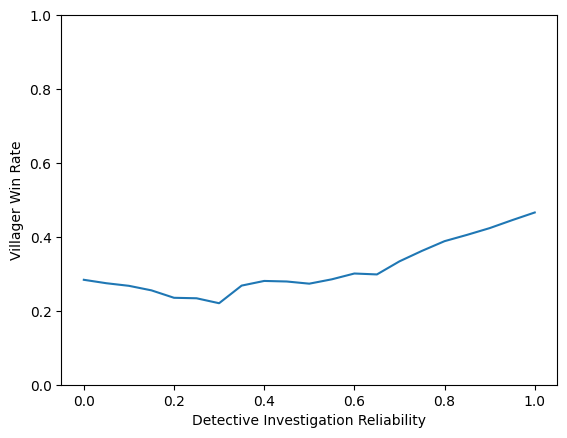

In [5]:
import matplotlib.pyplot as plt
from tqdm import tqdm

results = {}
reliabilities = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
num_games = 10000

for reliability in tqdm(reliabilities):
  villager_wins = 0

  for i in range(num_games):
    game = Game(reliability)
    result = game.play()
    if result["winner"] == "Villager":
      villager_wins += 1
  results[reliability] = villager_wins / num_games

for reliability, win_rate in results.items():
  print("Reliability:", reliability, ", Villager Win Rate:", win_rate)

plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0,1)
plt.show()

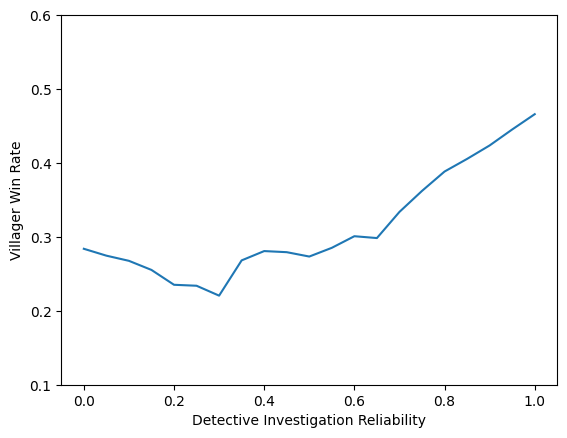

In [6]:
plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0.1,0.6)
plt.show()